In [73]:
import numpy as np
import pandas as pd
import h5py
import os

import matplotlib.pyplot as plt
from matplotlib import cm
import plotly.graph_objects as go

import sys

from eazy import photoz
from eazy import hdf5 as eazyh5

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits

from scipy import stats

In [74]:
"""
plot_style.py
-------------
Master matplotlib/plotly style loader.
Usage:
    from plot_style import *
    from plot_style import get_n_colors, MidFactor
"""

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import ScalarFormatter, LogLocator
from matplotlib.colors import to_rgba
from matplotlib.gridspec import GridSpec
import matplotlib.patheffects as path_effects
import plotly.graph_objects as go
from matplotlib.lines import Line2D
import matplotlib.patches as Patches
from matplotlib.legend_handler import HandlerTuple
import matplotlib.patheffects as pe

# ── RC Params ─────────────────────────────────────────────────────────────────
params = {
        # Font
        "font.family":          "serif",
        "font.size":            24,
        "text.usetex":          True,

        # Tick labels
        "xtick.labelsize":      20,
        "ytick.labelsize":      20,

        # Tick direction & size
        "xtick.direction":      "in",
        "ytick.direction":      "in",
        "xtick.major.size":     7,
        "ytick.major.size":     7,
        "xtick.minor.size":     3.5,
        "ytick.minor.size":     3.5,
        "xtick.minor.visible":  False,
        "ytick.minor.visible":  False,

        # Tick padding & axes
        "xtick.major.pad":      7,
        "axes.linewidth":       2.0,

        # tight layout
        "figure.constrained_layout.use": True
    }

plt.rcParams.update(params)


In [75]:
def compute_sigmaNMAD(zspec, zphot):
    deltaz = zphot - zspec
    sigmaNMAD = 1.48 * np.median( np.abs( (deltaz - np.median(deltaz)) / (1+zspec) ) )
    return sigmaNMAD

def compute_outliers(zspec, zphot):
    thresh = 0.15

    deltaz = abs(zphot - zspec)
    Noutlier = sum(deltaz > thresh * (1+zspec))
    print(Noutlier)
    print(len(zspec))
    outlier_frac = Noutlier / len(zspec)
    return outlier_frac

def compute_Nsigma_outliers(zspec, zphot, zphot_err, thresh = 2.0):

    deltaz = (abs(zphot - zspec))/zphot_err
    outlier_frac = sum(deltaz >= thresh) / len(zspec)
    
    return outlier_frac

In [76]:
new = eazyh5.initialize_from_hdf5(h5file='/Users/jordan/Documents/Epochs/data/eazy/miri_agn_blue_sfhz/miri_zphot_agn_blue_sfhz.out.h5')
new_app = eazyh5.initialize_from_hdf5(h5file='/Users/jordan/Documents/Epochs/data/eazy/miri_agn_blue_sfhz_32asec/miri_zphot_agn_blue_sfhz_32asec.out.h5')
new_col = eazyh5.initialize_from_hdf5(h5file='/Users/jordan/Documents/Epochs/data/eazy/miri_agn_blue_sfhz_col/miri_zphot_agn_blue_sfhz_col.out.h5')

set param: ADD_CGM y
set param: APPLY_IGM y
set param: APPLY_PRIOR n
set param: ARRAY_NBITS 32.0
set param: BINARY_OUTPUT y
set param: CACHE_FILE photz.tempfilt
set param: CATALOG_FILE /Users/jordan/Documents/Epochs/data/eazy/miri_phot_eazy.csv
set param: CATALOG_FORMAT ascii.commented_header
set param: CAT_HAS_EXTCORR True
set param: CHI2_SCALE 1.0
set param: DUMP_TEMPLATE_CACHE n
set param: FILTERS_RES FILTER.RES.latest
set param: FILTER_FORMAT 1.0
set param: FITTER nnls
set param: FIX_ZSPEC n
set param: GET_ZP_OFFSETS n
set param: H0 70.0
set param: HESS_THRESHOLD 1.0
set param: IGM_SCALE_TAU 1.0
set param: MAGNITUDES n
set param: MAIN_OUTPUT_FILE /Users/jordan/Documents/Epochs/data/eazy/miri_agn_blue_sfhz/miri_zphot_agn_blue_sfhz.out
set param: MW_EBV 0.0
set param: NMF_TOLERANCE 0.0001
set param: NOT_OBS_THRESHOLD -90
set param: N_MIN_COLORS 5.0
set param: OBS_SED_FILE n
set param: OMEGA_L 0.7
set param: OMEGA_M 0.3
set param: OUTPUT_DIRECTORY /Users/jordan/Documents/Epochs/data/e

CATALOG_FILE is a table
   >>> NOBJ = 6964
F435W_fluxt F435W_scaled_fluxt_err (233): hst/ACS_update_sep07/wfc_f435w_t81.dat
F606W_fluxt F606W_scaled_fluxt_err (236): hst/ACS_update_sep07/wfc_f606w_t81.dat
F070W_fluxt F070W_scaled_fluxt_err (362): jwst_nircam_f070w
F775W_fluxt F775W_scaled_fluxt_err (238): hst/ACS_update_sep07/wfc_f775w_t81.dat
F814W_fluxt F814W_scaled_fluxt_err (239): hst/ACS_update_sep07/wfc_f814w_t81.dat
F090W_fluxt F090W_scaled_fluxt_err (363): jwst_nircam_f090w
F850LP_fluxt F850LP_scaled_fluxt_err (240): hst/ACS_update_sep07/wfc_f850lp_t81.dat
F115W_fluxt F115W_scaled_fluxt_err (364): jwst_nircam_f115w
F150W_fluxt F150W_scaled_fluxt_err (365): jwst_nircam_f150w
F162M_fluxt F162M_scaled_fluxt_err (369): jwst_nircam_f162m
F182M_fluxt F182M_scaled_fluxt_err (370): jwst_nircam_f182m
F200W_fluxt F200W_scaled_fluxt_err (366): jwst_nircam_f200w
F210M_fluxt F210M_scaled_fluxt_err (371): jwst_nircam_f210m
F250M_fluxt F250M_scaled_fluxt_err (379): jwst_nircam_f250m
F277W_flu

371it [00:00, 1195.88it/s]


h5: read corr_sfhz_13_bin0_av0.01.fits
h5: read corr_sfhz_13_bin0_av0.25.fits
h5: read corr_sfhz_13_bin0_av0.50.fits
h5: read corr_sfhz_13_bin0_av1.00.fits
h5: read corr_sfhz_13_bin1_av0.01.fits
h5: read corr_sfhz_13_bin1_av0.25.fits
h5: read corr_sfhz_13_bin1_av0.50.fits
h5: read corr_sfhz_13_bin1_av1.00.fits
h5: read corr_sfhz_13_bin2_av0.01.fits
h5: read corr_sfhz_13_bin2_av0.50.fits
h5: read corr_sfhz_13_bin2_av1.00.fits
h5: read corr_sfhz_13_bin3_av0.01.fits
h5: read corr_sfhz_13_bin3_av0.50.fits
h5: read fsps_4590.fits
h5: read j0647agn+torus.fits
fit_best: 0.2 s (n_proc=1,  NOBJ=6508)
set param: ADD_CGM y
set param: APPLY_IGM y
set param: APPLY_PRIOR n
set param: ARRAY_NBITS 32.0
set param: BINARY_OUTPUT y
set param: CACHE_FILE photz.tempfilt
set param: CATALOG_FILE /Users/jordan/Documents/Epochs/data/eazy/miri_phot_eazy.csv
set param: CATALOG_FORMAT ascii.commented_header
set param: CAT_HAS_EXTCORR True
set param: CHI2_SCALE 1.0
set param: DUMP_TEMPLATE_CACHE n
set param: FILTE

CATALOG_FILE is a table
   >>> NOBJ = 6964
F435W_flux_app_0.32 F435W_scaled_flux_err_app_0.32 (233): hst/ACS_update_sep07/wfc_f435w_t81.dat
F606W_flux_app_0.32 F606W_scaled_flux_err_app_0.32 (236): hst/ACS_update_sep07/wfc_f606w_t81.dat
F070W_flux_app_0.32 F070W_scaled_flux_err_app_0.32 (362): jwst_nircam_f070w
F775W_flux_app_0.32 F775W_scaled_flux_err_app_0.32 (238): hst/ACS_update_sep07/wfc_f775w_t81.dat
F814W_flux_app_0.32 F814W_scaled_flux_err_app_0.32 (239): hst/ACS_update_sep07/wfc_f814w_t81.dat
F090W_flux_app_0.32 F090W_scaled_flux_err_app_0.32 (363): jwst_nircam_f090w
F850LP_flux_app_0.32 F850LP_scaled_flux_err_app_0.32 (240): hst/ACS_update_sep07/wfc_f850lp_t81.dat
F115W_flux_app_0.32 F115W_scaled_flux_err_app_0.32 (364): jwst_nircam_f115w
F150W_flux_app_0.32 F150W_scaled_flux_err_app_0.32 (365): jwst_nircam_f150w
F162M_flux_app_0.32 F162M_scaled_flux_err_app_0.32 (369): jwst_nircam_f162m
F182M_flux_app_0.32 F182M_scaled_flux_err_app_0.32 (370): jwst_nircam_f182m
F200W_flux_ap

371it [00:00, 1148.70it/s]


h5: read corr_sfhz_13_bin0_av0.01.fits
h5: read corr_sfhz_13_bin0_av0.25.fits
h5: read corr_sfhz_13_bin0_av0.50.fits
h5: read corr_sfhz_13_bin0_av1.00.fits
h5: read corr_sfhz_13_bin1_av0.01.fits
h5: read corr_sfhz_13_bin1_av0.25.fits
h5: read corr_sfhz_13_bin1_av0.50.fits
h5: read corr_sfhz_13_bin1_av1.00.fits
h5: read corr_sfhz_13_bin2_av0.01.fits
h5: read corr_sfhz_13_bin2_av0.50.fits
h5: read corr_sfhz_13_bin2_av1.00.fits
h5: read corr_sfhz_13_bin3_av0.01.fits
h5: read corr_sfhz_13_bin3_av0.50.fits
h5: read fsps_4590.fits
h5: read j0647agn+torus.fits
fit_best: 0.2 s (n_proc=1,  NOBJ=6450)
set param: ADD_CGM y
set param: APPLY_IGM y
set param: APPLY_PRIOR n
set param: ARRAY_NBITS 32.0
set param: BINARY_OUTPUT y
set param: CACHE_FILE photz.tempfilt
set param: CATALOG_FILE /Users/jordan/Documents/Epochs/data/eazy/miri_phot_eazy.csv
set param: CATALOG_FORMAT ascii.commented_header
set param: CAT_HAS_EXTCORR True
set param: CHI2_SCALE 1.0
set param: DUMP_TEMPLATE_CACHE n
set param: FILTE

CATALOG_FILE is a table
   >>> NOBJ = 6964
F435W_fluxc F435W_scaled_fluxc_err (233): hst/ACS_update_sep07/wfc_f435w_t81.dat
F606W_fluxc F606W_scaled_fluxc_err (236): hst/ACS_update_sep07/wfc_f606w_t81.dat
F070W_fluxc F070W_scaled_fluxc_err (362): jwst_nircam_f070w
F775W_fluxc F775W_scaled_fluxc_err (238): hst/ACS_update_sep07/wfc_f775w_t81.dat
F814W_fluxc F814W_scaled_fluxc_err (239): hst/ACS_update_sep07/wfc_f814w_t81.dat
F090W_fluxc F090W_scaled_fluxc_err (363): jwst_nircam_f090w
F850LP_fluxc F850LP_scaled_fluxc_err (240): hst/ACS_update_sep07/wfc_f850lp_t81.dat
F115W_fluxc F115W_scaled_fluxc_err (364): jwst_nircam_f115w
F150W_fluxc F150W_scaled_fluxc_err (365): jwst_nircam_f150w
F162M_fluxc F162M_scaled_fluxc_err (369): jwst_nircam_f162m
F182M_fluxc F182M_scaled_fluxc_err (370): jwst_nircam_f182m
F200W_fluxc F200W_scaled_fluxc_err (366): jwst_nircam_f200w
F210M_fluxc F210M_scaled_fluxc_err (371): jwst_nircam_f210m
F250M_fluxc F250M_scaled_fluxc_err (379): jwst_nircam_f250m
F277W_flu

371it [00:00, 1199.15it/s]


h5: read corr_sfhz_13_bin0_av0.01.fits
h5: read corr_sfhz_13_bin0_av0.25.fits
h5: read corr_sfhz_13_bin0_av0.50.fits
h5: read corr_sfhz_13_bin0_av1.00.fits
h5: read corr_sfhz_13_bin1_av0.01.fits
h5: read corr_sfhz_13_bin1_av0.25.fits
h5: read corr_sfhz_13_bin1_av0.50.fits
h5: read corr_sfhz_13_bin1_av1.00.fits
h5: read corr_sfhz_13_bin2_av0.01.fits
h5: read corr_sfhz_13_bin2_av0.50.fits
h5: read corr_sfhz_13_bin2_av1.00.fits
h5: read corr_sfhz_13_bin3_av0.01.fits
h5: read corr_sfhz_13_bin3_av0.50.fits
h5: read fsps_4590.fits
h5: read j0647agn+torus.fits
fit_best: 0.2 s (n_proc=1,  NOBJ=6214)


6489
6964
6468
6964
6451
6964


/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_3360/2390234065.py:3: RuntimeWarning: divide by zero encountered in divide
  sigmaNMAD = 1.48 * np.median( np.abs( (deltaz - np.median(deltaz)) / (1+zspec) ) )


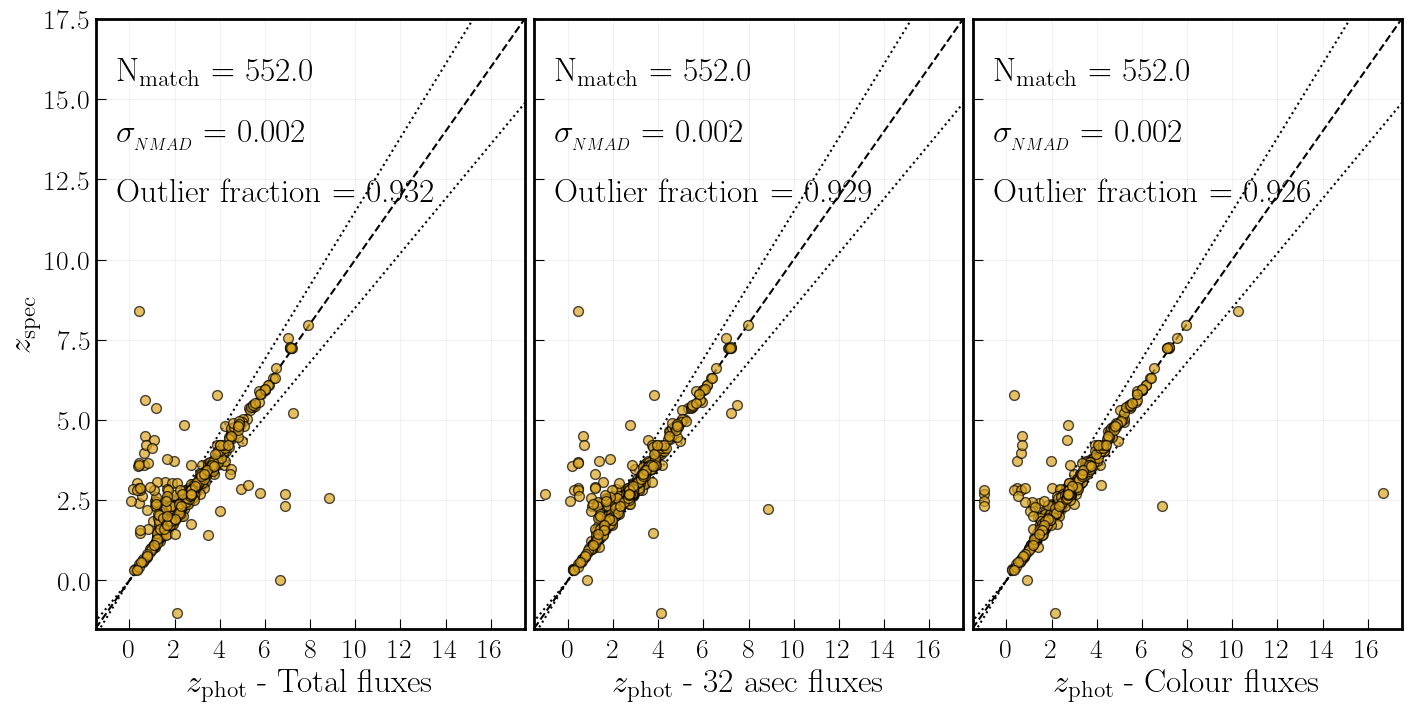

In [80]:
fig, axs = plt.subplots(1, 3, figsize = (14,7), sharey = True)

def plot_zz(new, ax):
    zbest_leg = ax.scatter(
        new.zml,
        new.ZSPEC,
        s = 50, 
        zorder = 20, 
        edgecolor = "black",
        facecolor = "goldenrod",
        alpha = 0.7,
        label = "zbest"
    )
    ax.text(
        0.05, 0.90, 
        rf"N$_{{\mathrm{{match}}}}$ =  {len(new.ZSPEC[new.ZSPEC > 0]):.1f}", transform=ax.transAxes
    )
    ax.text(
        0.05, 0.80, 
        rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=new.ZSPEC, zphot=new.zml):.3f}", transform=ax.transAxes
    )
    ax.text(
        0.05, 0.70, 
        rf"Outlier fraction = {compute_outliers(zspec=new.ZSPEC, zphot=new.zml):.3f}", transform=ax.transAxes
    )

plot_zz(
    new,
    axs[0]
)
plot_zz(
    new_app, 
    axs[1]
)
plot_zz(
    new_col,
    axs[2]
)
for i, ax in enumerate(axs):
    
    ax.axline((0, 0), slope=1, 
                color='black', linestyle='--'
    )
    ax.set_xlim([-1.5, 17.5]),
    ax.set_ylim([-1.5, 17.5])
    # ax.set_yticks([0, 5, 10, 15, 20, 25])


    ax.plot(np.linspace(-400, 400, 40) + 1, 1.15 * (np.linspace(-400, 400, 40) + 1), 
            color='black', linestyle=':'
    )
    ax.plot(np.linspace(-400, 400, 40) + 1, 0.85 * (np.linspace(-400, 400, 40) + 1), 
            color='black', linestyle=':'
    )
    ax.set_xticks([0,2,4,6,8,10,12,14,16])

    ax.grid(color = 'grey', alpha = 0.1, ls = "-")

axs[0].set_xlabel(r'$z_{\mathrm{phot}}$ - Total fluxes')
axs[1].set_xlabel(r'$z_{\mathrm{phot}}$ - 32 asec fluxes')
axs[2].set_xlabel(r'$z_{\mathrm{phot}}$ - Colour fluxes')

axs[0].set_ylabel(r"$z_{\mathrm{spec}}$")

fig.align_labels() # Aligns the labels
# fig.tight_layout()


# fig.savefig("/Users/jordan/Documents/Epochs/plots/smiles_zspec_zphot.pdf", bbox_inches = 'tight')